In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
sys.path.append(os.path.split(os.getcwd())[0])
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scripts.load import load_CCCA_adata

In [2]:
name = 'Puram2017_Head-and-Neck'
pth = os.path.join('..', '..', '..', '..')
pth_in = os.path.join(pth, 'data', 'unzip', 'CCCA', f'Data_{name}')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', name)

In [3]:
adata = load_CCCA_adata(pth_in)
msk = (adata.obs.celltype == 'Malignant')
adata = adata[msk].copy(); adata

Loading ../../../../data/unzip/CCCA/Data_Puram2017_Head-and-Neck
Done.


AnnData object with n_obs × n_vars = 2539 × 23686
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype'
    uns: 'log1p'

In [26]:
adata.obs['sample-and-source'] = adata.obs['sample'].astype(str) + '_' + adata.obs.source.astype(str)

In [27]:
n = adata.obs['sample-and-source'].value_counts(); n

sample-and-source
17_Primary       353
20_Lymph_node    345
20_Primary       331
18_Primary       263
26_Lymph_node    223
6_Primary        157
25_Primary       153
22_Primary       123
16_Primary       100
28_Lymph_node    100
25_Lymph_node     76
5_Primary         70
5_Lymph_node      68
26_Primary        61
28_Primary        49
Name: count, dtype: int64

In [10]:
keep = n.index[n >= 100]
msk = adata.obs['sample'].isin(keep)
adata = adata[msk].copy(); adata

AnnData object with n_obs × n_vars = 2472 × 23686
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'celltype'
    uns: 'log1p'

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4804 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.



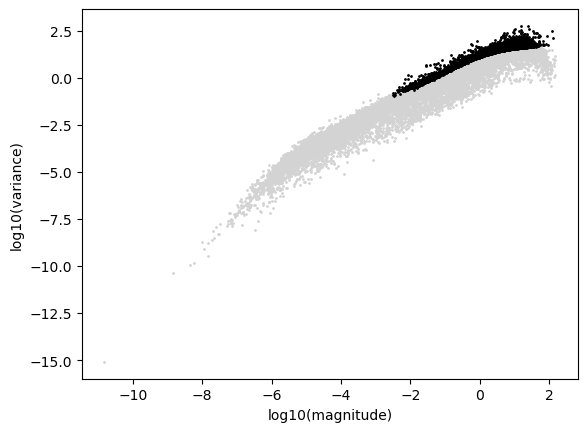

In [11]:
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata, plot = True)

In [12]:
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'sample')

2026-07-04 22:31:07,885 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-04 22:31:08,553 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-04 22:31:08,579 - harmonypy - INFO - Iteration 1 of 10
2026-07-04 22:31:09,095 - harmonypy - INFO - Iteration 2 of 10
2026-07-04 22:31:09,576 - harmonypy - INFO - Iteration 3 of 10
2026-07-04 22:31:10,056 - harmonypy - INFO - Iteration 4 of 10
2026-07-04 22:31:10,528 - harmonypy - INFO - Iteration 5 of 10
2026-07-04 22:31:11,005 - harmonypy - INFO - Iteration 6 of 10
2026-07-04 22:31:11,477 - harmonypy - INFO - Converged after 6 iterations


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


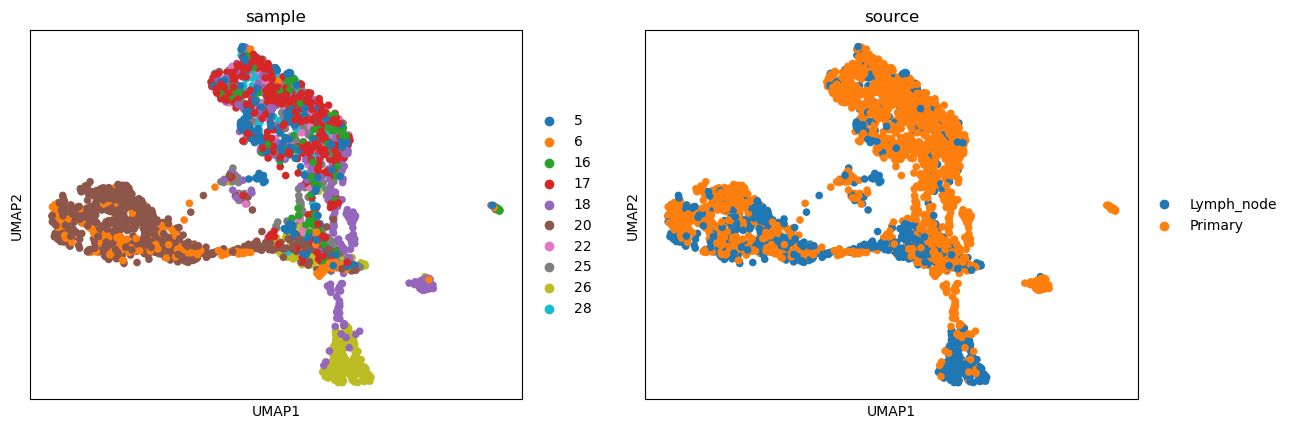

In [13]:
sc.pp.neighbors(adata, n_pcs = 40, use_rep = 'X_pca_harmony')
sc.tl.umap(adata, spread = 2.5)
sc.pl.umap(adata, color = ['sample', 'source'], size = 120)

In [ ]:
sc.tl.leiden(adata)
sc.pl.umap(adata, color = 'leiden', size = 30, legend_loc = 'on data', legend_fontoutline = True)

In [ ]:
sc.pl.umap(adata, color = ['EPCAM', 'VIM'], size = 120)

In [ ]:
# remove = np.array([7, 10, 13, 11, 14, 6], dtype = str)
# adata = adata[~adata.obs.leiden.isin(remove)].copy()
# adata